# Homework # 4 Naive BAYES Classifier

### Instructor - Dr. Uma Gajendragadkar

### Problem - Design and develop Machine learning model to predict Diabetes using Naive Bayes Algorithm. 

### Dataset - Diabetes dataset

This dataset consists of 768 observations & 8 numerical independent variables.
Dependent and target variable is OUTCOME. 1 means diabetes test result being positive, 0 means indicates negative.

Pregnancies: Number of Times Being Pregnant

Glucose: Plasma Glucose Concentration (a 2 hours in an oral glucose tolerance test)

BloodPressure: Diastolic Blood Pressure (mm Hg)

SkinThickness: Triceps Skin Fold Thickness (mm)

Insulin: 2-Hour Serum Insulin (mu U/ml)

BMI: Body Mass Index (weight in kg/(height in m)^2)

DiabetesPedigreeFunction: Diabetes Pedigree Function

Age: Age

Outcome: Class variable ( 0 - 1)



**Target variable:** `Outcome` (0 = negative, 1 = positive). The notebook follows the provided starter instruction to remove `Pregnancies` before training.

**Note:** This is an educational classification exercise, not a medical diagnostic tool.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_auc_score, RocCurveDisplay
)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")


### Step 1 - Read the dataset into a pandas DataFrame

In [2]:
# Read the diabetes dataset.
# Keep the CSV file in the same folder as this notebook.
data = pd.read_csv("diabetes(1).csv")

print("Dataset loaded successfully.")
print("Dataset shape:", data.shape)
data.head()

Dataset loaded successfully.
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1


### Step 2 - Explore the dataset

Display the dataset information, the first 10 rows, summary statistics, missing-value counts, and visualizations.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1
5,5,116,74,0,0,25.600,0.201,30,0
6,3,78,50,32,88,31.000,0.248,26,1
7,10,115,0,0,0,35.300,0.134,29,0
8,2,197,70,45,543,30.500,0.158,53,1
9,8,125,96,0,0,0.000,0.232,54,1


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000
mean,3.845,120.895,69.105,20.536,79.799,31.993,0.472,33.241,0.349
std,3.370,31.973,19.356,15.952,115.244,7.884,0.331,11.760,0.477
min,0.000,0.000,0.000,0.000,0.000,0.000,0.078,21.000,0.000
25%,1.000,99.000,62.000,0.000,0.000,27.300,0.244,24.000,0.000
50%,3.000,117.000,72.000,23.000,30.500,32.000,0.372,29.000,0.000
75%,6.000,140.250,80.000,32.000,127.250,36.600,0.626,41.000,1.000
max,17.000,199.000,122.000,99.000,846.000,67.100,2.420,81.000,1.000


Missing values by column:


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

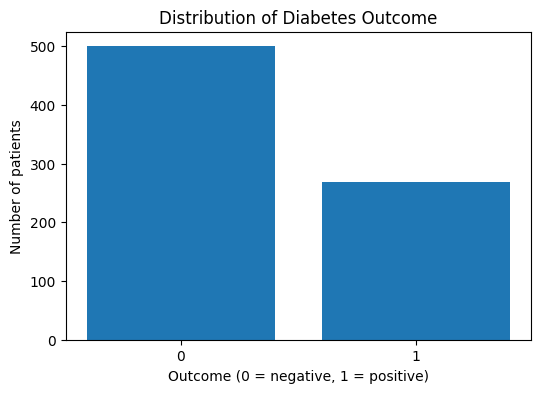

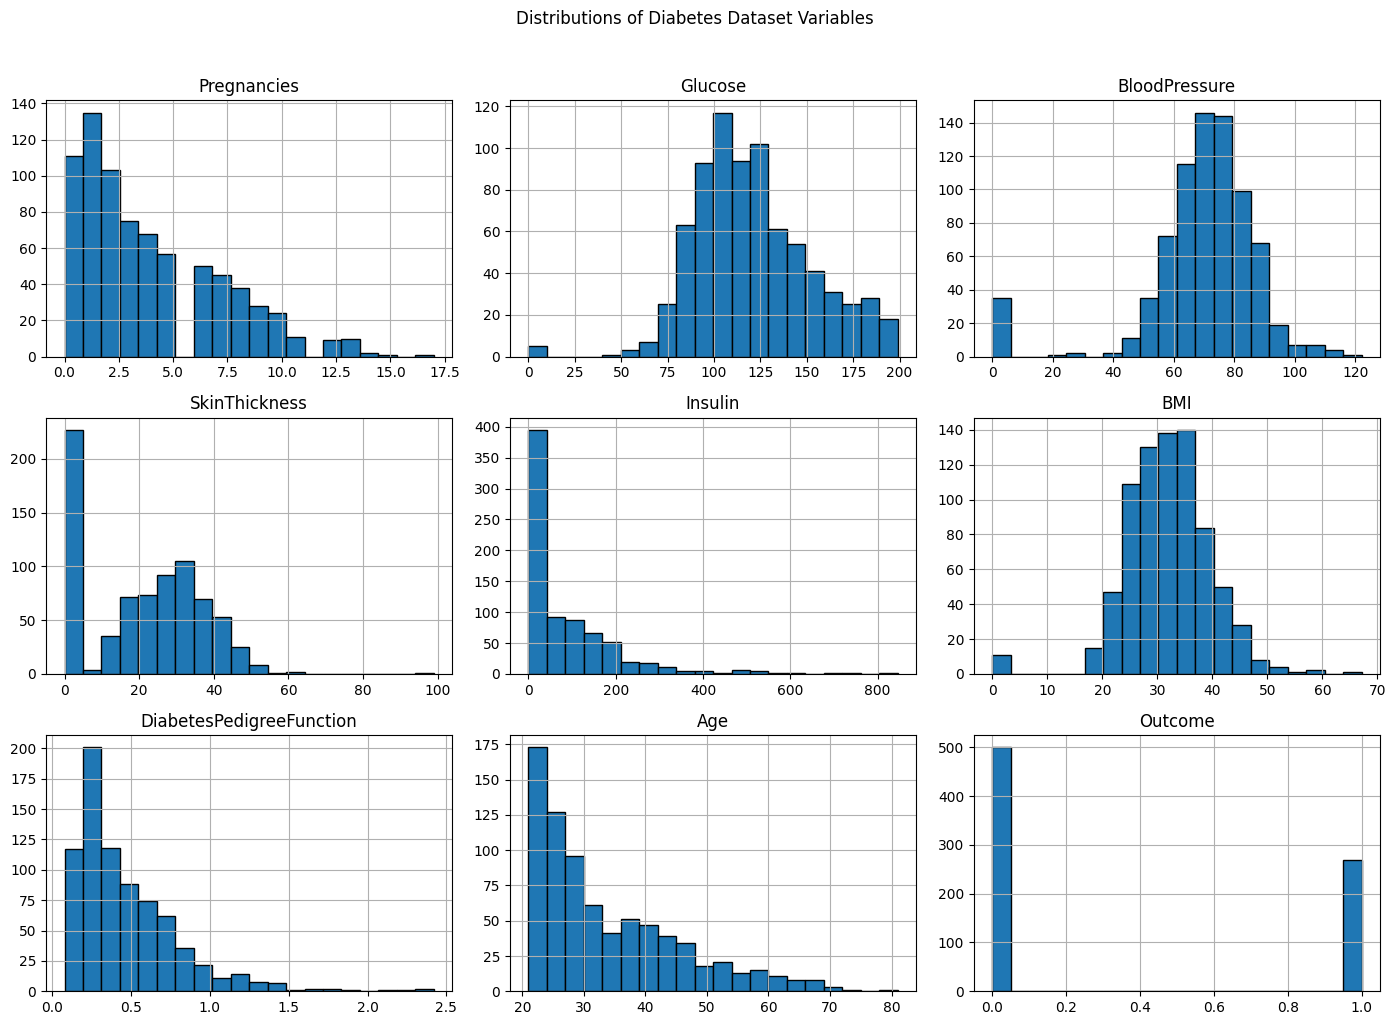

<Figure size 1000x700 with 0 Axes>

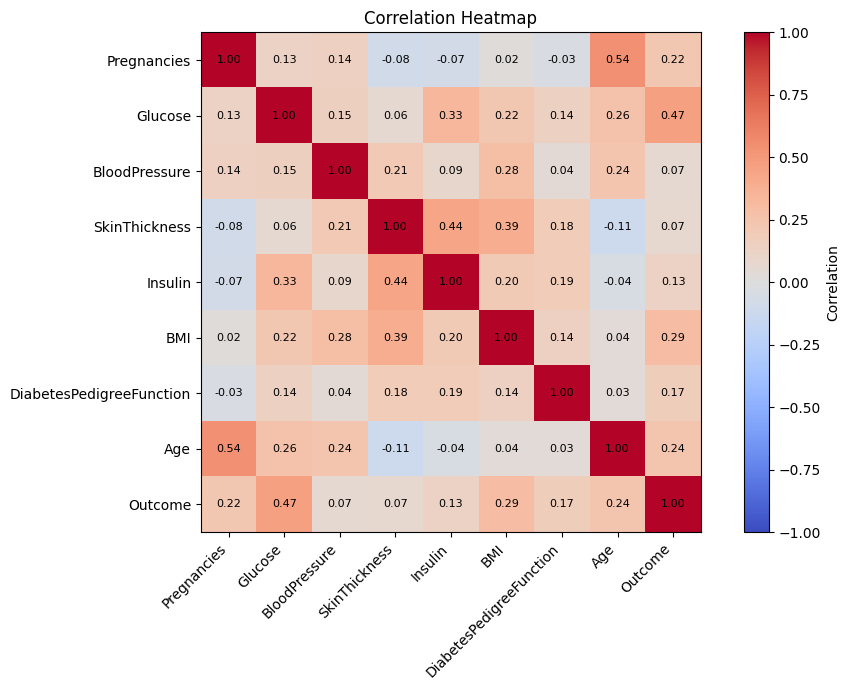

In [3]:
# a) Review the dataset structure and data types.
data.info()

# b) Display the first 10 rows.
display(data.head(10))

# Summary statistics help identify unusual values and differences in scale.
display(data.describe())

# Check for missing values in each column.
print("Missing values by column:")
display(data.isnull().sum())

# Explore the target distribution.
plt.figure(figsize=(6, 4))
outcome_counts = data["Outcome"].value_counts().sort_index()
plt.bar(outcome_counts.index.astype(str), outcome_counts.values)
plt.title("Distribution of Diabetes Outcome")
plt.xlabel("Outcome (0 = negative, 1 = positive)")
plt.ylabel("Number of patients")
plt.xticks([0, 1], ["0", "1"])
plt.show()

# Explore the distributions of the numerical features.
data.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distributions of Diabetes Dataset Variables", y=1.02)
plt.tight_layout()
plt.show()

# Correlations provide a quick view of relationships among numeric variables.
plt.figure(figsize=(10, 7))
correlations = data.corr(numeric_only=True)
plt.figure(figsize=(10, 7))
image = plt.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(image, label="Correlation")
plt.xticks(range(len(correlations.columns)), correlations.columns, rotation=45, ha="right")
plt.yticks(range(len(correlations.columns)), correlations.columns)
for row in range(len(correlations.columns)):
    for column in range(len(correlations.columns)):
        plt.text(column, row, f"{correlations.iloc[row, column]:.2f}",
                 ha="center", va="center", fontsize=8)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Step 3 - Remove the Pregnancies column

In [4]:
# The starter notebook specifically asks us to remove the Pregnancies column.
data = data.drop(columns=["Pregnancies"])
print("Pregnancies column removed.")
print("Remaining columns:", data.columns.tolist())

Pregnancies column removed.
Remaining columns: ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


### Step 4 - Display the updated dataset information and shape

In [5]:
# Check the updated dataset's dimensions and information.
print("Updated dataset shape:", data.shape)
data.info()
display(data.head())

Updated dataset shape: (768, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Glucose                   768 non-null    int64  
 1   BloodPressure             768 non-null    int64  
 2   SkinThickness             768 non-null    int64  
 3   Insulin                   768 non-null    int64  
 4   BMI                       768 non-null    float64
 5   DiabetesPedigreeFunction  768 non-null    float64
 6   Age                       768 non-null    int64  
 7   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(6)
memory usage: 48.1 KB


,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,72,35,0,33.600,0.627,50,1
1,85,66,29,0,26.600,0.351,31,0
2,183,64,0,0,23.300,0.672,32,1
3,89,66,23,94,28.100,0.167,21,0
4,137,40,35,168,43.100,2.288,33,1


### Step 5 - Clean the data

The dataset uses zero values for some measurements that cannot realistically be zero. These are treated as missing and filled with the median of their respective columns.

In [6]:
# In this dataset, zero is not a realistic measurement for these five
# medical features. Treat those zeros as missing values and impute them
# with each column's median. Outcome is not included in this replacement.
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

data[zero_as_missing] = data[zero_as_missing].replace(0, np.nan)

print("Missing values after replacing impossible zero measurements:")
display(data.isnull().sum())

# Median imputation is less sensitive to extreme values than mean imputation.
for column in zero_as_missing:
    data[column] = data[column].fillna(data[column].median())

print("Missing values after median imputation:")
display(data.isnull().sum())

# Confirm that the target still contains the two expected classes.
print("Outcome counts:")
display(data["Outcome"].value_counts().sort_index())

# Show the cleaned data.
display(data.head())

Missing values after replacing impossible zero measurements:


Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Missing values after median imputation:


Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Outcome counts:


Outcome
0    500
1    268
Name: count, dtype: int64

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148.000,72.000,35.000,125.000,33.600,0.627,50,1
1,85.000,66.000,29.000,125.000,26.600,0.351,31,0
2,183.000,64.000,29.000,125.000,23.300,0.672,32,1
3,89.000,66.000,23.000,94.000,28.100,0.167,21,0
4,137.000,40.000,35.000,168.000,43.100,2.288,33,1


### Step 6 - Split the data into training and testing sets (80:20)

In [7]:
# Separate input features (X) from the target label (y).
X = data.drop(columns=["Outcome"])
y = data["Outcome"]

# Split 80% for training and 20% for testing.
# stratify=y keeps the class proportions similar in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (614, 7)
Testing feature shape: (154, 7)
Training target shape: (614,)
Testing target shape: (154,)


### Step 7 - Initialize the Gaussian Naive Bayes model

In [8]:
# Gaussian Naive Bayes is appropriate for continuous numerical features.
model = GaussianNB()
print(model)

GaussianNB()


### Step 8 - Fit the model and evaluate predictions on the testing data

In [9]:
# Train the model using the training data.
model.fit(X_train, y_train)

# Generate predictions for the held-out testing data.
y_pred = model.predict(X_test)

print("Model training and prediction completed.")

Model training and prediction completed.


### Step 9 - Predict using the model on the test data

In [10]:
# Predict the outcome for each patient in the test set.
predictions = pd.DataFrame({
    "Actual Outcome": y_test.values,
    "Predicted Outcome": y_pred
}, index=y_test.index)

display(predictions.head(15))

,Actual Outcome,Predicted Outcome
44,0,0
672,0,0
700,0,0
630,1,0
81,0,0
389,0,0
387,1,1
408,1,1
163,0,0
335,0,1


### Step 10 - Find the accuracy and other evaluation metrics

Test accuracy: 0.688 (68.8%)

Classification report:
                 precision    recall  f1-score   support

No diabetes (0)       0.75      0.77      0.76       100
   Diabetes (1)       0.56      0.54      0.55        54

       accuracy                           0.69       154
      macro avg       0.66      0.65      0.65       154
   weighted avg       0.69      0.69      0.69       154

ROC-AUC: 0.750


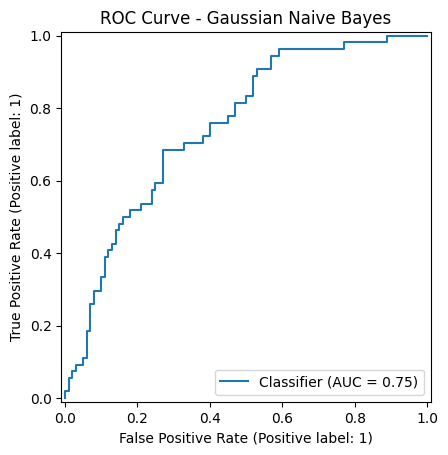

In [11]:
# Calculate classification accuracy.
accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.3f} ({accuracy * 100:.1f}%)")

# Precision, recall, and F1-score give additional information beyond accuracy.
print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    target_names=["No diabetes (0)", "Diabetes (1)"],
    zero_division=0
))

# ROC-AUC evaluates how well the model separates the two classes.
y_probability = model.predict_proba(X_test)[:, 1]
print(f"ROC-AUC: {roc_auc_score(y_test, y_probability):.3f}")

RocCurveDisplay.from_predictions(y_test, y_probability)
plt.title("ROC Curve - Gaussian Naive Bayes")
plt.show()

### Step 11 - Display the confusion matrix

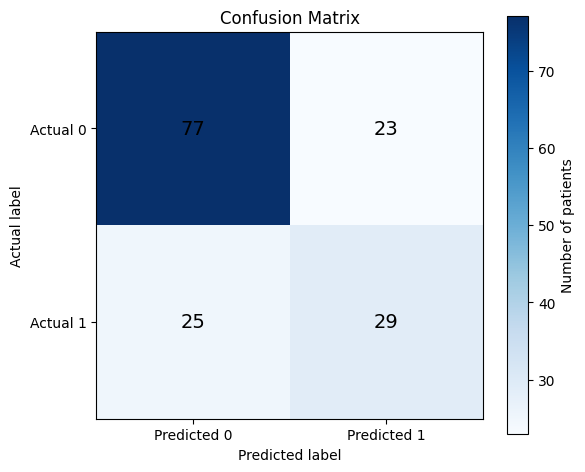

Confusion matrix:
[[77 23]
 [25 29]]


In [12]:
# A confusion matrix compares actual labels with predicted labels.
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.colorbar(label="Number of patients")
plt.xticks([0, 1], ["Predicted 0", "Predicted 1"])
plt.yticks([0, 1], ["Actual 0", "Actual 1"])
for row in range(2):
    for column in range(2):
        plt.text(column, row, str(cm[row, column]),
                 ha="center", va="center", fontsize=14)
plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)

In [13]:
# Interpretation:
# - True negatives: patients without diabetes correctly predicted as 0.
# - False positives: patients without diabetes predicted as 1.
# - False negatives: patients with diabetes predicted as 0.
# - True positives: patients with diabetes correctly predicted as 1.
#
# This is a classroom model using a limited dataset. Its predictions should
# not be used as a medical diagnosis or as a substitute for clinical testing.